Loading the Dataset – import libraries and read EasyVisa.csv

In [76]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

if not os.path.exists("EasyVisa.csv"):
    from google.colab import files
    files.upload()

df = pd.read_csv("EasyVisa.csv")
print("Shape:", df.shape)
df.head()

Shape: (25480, 12)


,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


Dataset Overview – column types, missing values and duplicates

In [77]:
df.info()
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB

Missing values: 0
Duplicate rows: 0


,no_of_employees,yr_of_estab,prevailing_wage
count,25480.000000,25480.000000,25480.000000
mean,5667.043210,1979.409929,74455.814592
std,22877.928848,42.366929,52815.942327
min,-26.000000,1800.000000,2.136700
25%,1022.000000,1976.000000,34015.480000
50%,2109.000000,1997.000000,70308.210000
75%,3504.000000,2005.000000,107735.512500
max,602069.000000,2016.000000,319210.270000


Target Variable – how many Certified vs Denied

case_status
Certified    66.8
Denied       33.2
Name: proportion, dtype: float64


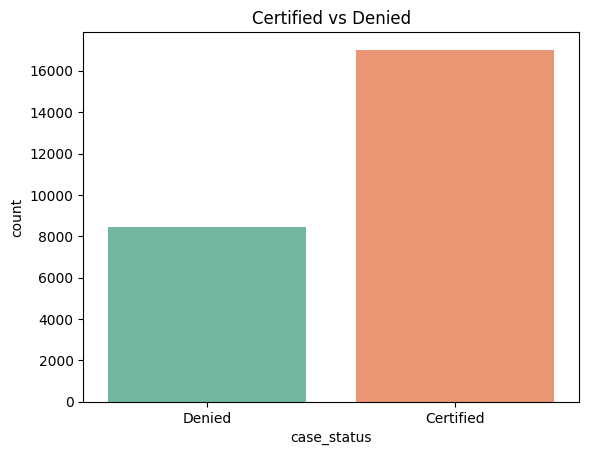

In [78]:
print(df["case_status"].value_counts(normalize=True).round(3) * 100)
sns.countplot(data=df, x="case_status", hue="case_status", palette="Set2", legend=False)
plt.title("Certified vs Denied")
plt.show()

EDA – approval rate by education, experience, wage unit and continent

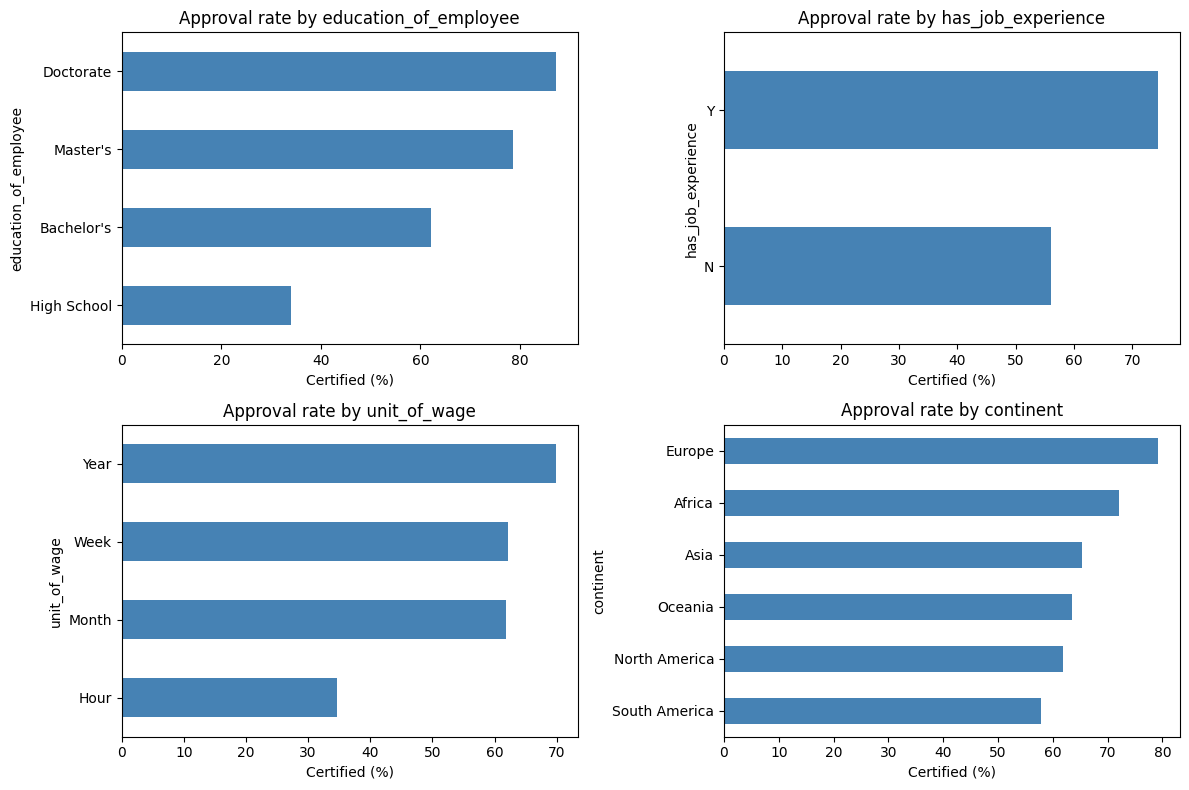

In [79]:
cols = ["education_of_employee", "has_job_experience", "unit_of_wage", "continent"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, cols):
    rate = df.groupby(col)["case_status"].apply(lambda s: (s == "Certified").mean() * 100).sort_values()
    rate.plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"Approval rate by {col}")
    ax.set_xlabel("Certified (%)")
plt.tight_layout()
plt.show()

EDA – distribution of number columns

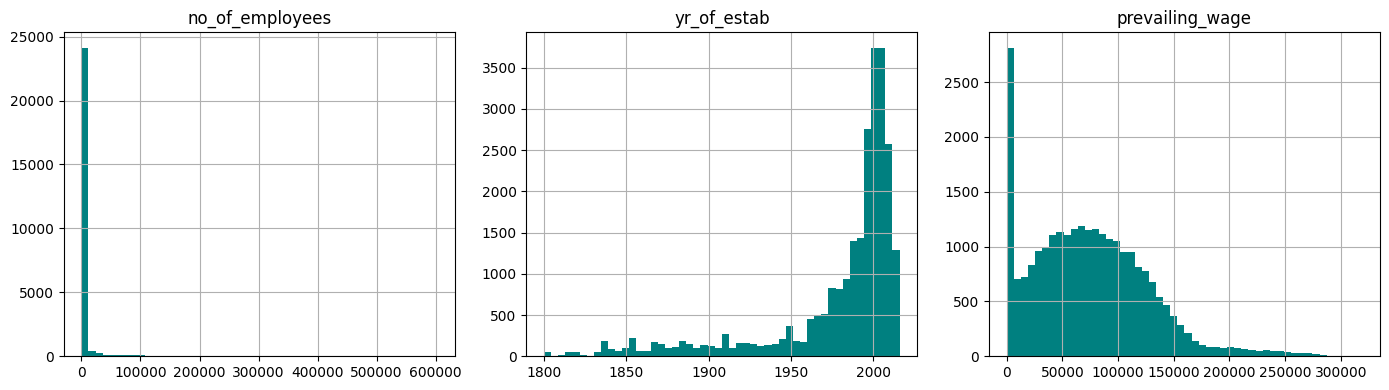

In [80]:
df[["no_of_employees", "yr_of_estab", "prevailing_wage"]].hist(bins=50, figsize=(14, 4), layout=(1, 3), color="teal")
plt.tight_layout()
plt.show()

Data Cleaning – drop ID column and fix negative employee counts

In [81]:
data = df.drop(columns=["case_id"])                          # ID column is not useful
data["no_of_employees"] = data["no_of_employees"].abs()      # fix negative values
print("Negative employee counts left:", (data["no_of_employees"] < 0).sum())

Negative employee counts left: 0


Feature Engineering – annual wage, company age and log transform

In [82]:
to_annual = {"Hour": 2080, "Week": 52, "Month": 12, "Year": 1}
data["annual_wage"] = data["prevailing_wage"] * data["unit_of_wage"].map(to_annual)
data["company_age"] = 2016 - data["yr_of_estab"]
data["log_annual_wage"] = np.log1p(data["annual_wage"])          # reduce extreme values
data["log_no_of_employees"] = np.log1p(data["no_of_employees"])
data[["prevailing_wage", "unit_of_wage", "annual_wage", "company_age"]].head()

,prevailing_wage,unit_of_wage,annual_wage,company_age
0,592.2029,Hour,1231782.032,9
1,83425.6500,Year,83425.650,14
2,122996.8600,Year,122996.860,8
3,83434.0300,Year,83434.030,119
4,149907.3900,Year,149907.390,11


Encoding – converting text columns into numbers

In [83]:
data["case_status"] = data["case_status"].map({"Certified": 1, "Denied": 0})
for col in ["has_job_experience", "requires_job_training", "full_time_position"]:
    data[col] = data[col].map({"Y": 1, "N": 0})
edu_order = {"High School": 0, "Bachelor's": 1, "Master's": 2, "Doctorate": 3}
data["education_of_employee"] = data["education_of_employee"].map(edu_order)
data = pd.get_dummies(data, columns=["continent", "region_of_employment", "unit_of_wage"], drop_first=True, dtype=int)
data = data.drop(columns=["prevailing_wage", "annual_wage", "no_of_employees", "yr_of_estab"])
print("Final shape:", data.shape)

Final shape: (25480, 20)


Feature Selection – correlation of each feature with approval

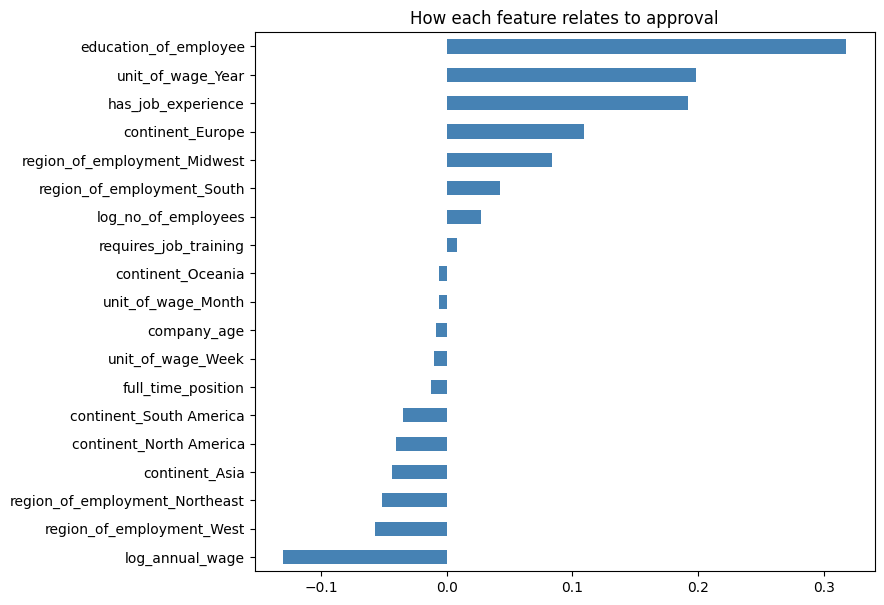

In [84]:
corr = data.corr()["case_status"].drop("case_status").sort_values()
corr.plot(kind="barh", figsize=(8, 7), color="steelblue")
plt.title("How each feature relates to approval")
plt.show()

Train-Test Split (80/20) and Feature Scaling

In [85]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.drop(columns=["case_status"])
y = data["case_status"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (20384, 19)  Test: (5096, 19)


Model Training – Logistic Regression (baseline) and evaluation

Accuracy: 72.4%
F1 Score: 0.809


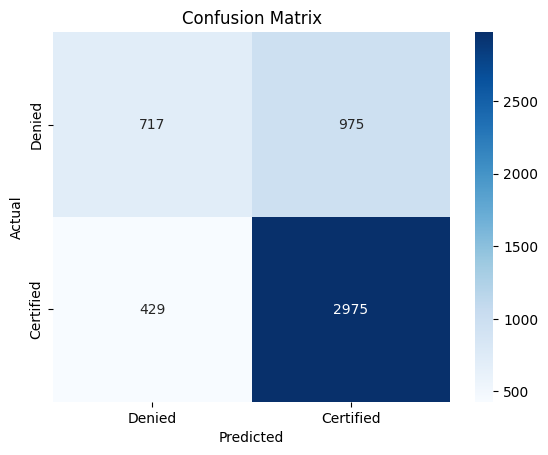

In [86]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)
y_pred = log_model.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.1%}")
print(f"F1 Score: {f1_score(y_test, y_pred):.3f}")

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Denied", "Certified"], yticklabels=["Denied", "Certified"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

 Model Persistence – saving and reloading with Joblib

In [87]:
import joblib
joblib.dump(log_model, "visa_model_part1.joblib")
loaded_model = joblib.load("visa_model_part1.joblib")
print("Model saved and reloaded. Same predictions:", (loaded_model.predict(X_test_scaled) == y_pred).all())

Model saved and reloaded. Same predictions: True


Predictions on New Unseen Applicants

In [88]:
new_applicants = pd.DataFrame([
    {"continent": "Europe", "education_of_employee": "Doctorate", "has_job_experience": "Y",
     "requires_job_training": "N", "no_of_employees": 5000, "yr_of_estab": 1995,
     "region_of_employment": "Midwest", "prevailing_wage": 95000, "unit_of_wage": "Year",
     "full_time_position": "Y"},
    {"continent": "Asia", "education_of_employee": "High School", "has_job_experience": "N",
     "requires_job_training": "N", "no_of_employees": 300, "yr_of_estab": 2010,
     "region_of_employment": "West", "prevailing_wage": 45, "unit_of_wage": "Hour",
     "full_time_position": "Y"},
])

# Apply the same steps as cells 6-8
new = new_applicants.copy()
new["annual_wage"] = new["prevailing_wage"] * new["unit_of_wage"].map(to_annual)
new["company_age"] = 2016 - new["yr_of_estab"]
new["log_annual_wage"] = np.log1p(new["annual_wage"])
new["log_no_of_employees"] = np.log1p(new["no_of_employees"])
for col in ["has_job_experience", "requires_job_training", "full_time_position"]:
    new[col] = new[col].map({"Y": 1, "N": 0})
new["education_of_employee"] = new["education_of_employee"].map(edu_order)
new = pd.get_dummies(new, columns=["continent", "region_of_employment", "unit_of_wage"], dtype=int)
new = new.reindex(columns=X.columns, fill_value=0)

probs = loaded_model.predict_proba(scaler.transform(new))[:, 1]
for i, p in enumerate(probs, start=1):
    print(f"Applicant {i}: {'CERTIFIED' if p >= 0.5 else 'DENIED'} ({p:.1%} chance of approval)")

Applicant 1: CERTIFIED (98.4% chance of approval)
Applicant 2: DENIED (6.4% chance of approval)


Training and Comparing Three Models

In [90]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

results = []
for name, m in models.items():
    m.fit(X_train_scaled, y_train)
    pred = m.predict(X_test_scaled)
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, pred),
                    "F1 Score": f1_score(y_test, pred)})

results = pd.DataFrame(results)
print(results.round(4))

                 Model  Accuracy  F1 Score
0  Logistic Regression    0.7245    0.8091
1        Random Forest    0.7223    0.8011
2    Gradient Boosting    0.7408    0.8178


Hyperparameter Tuning – GridSearchCV on Random Forest

In [91]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],      # number of trees
    "max_depth": [8, 12, None],      # how deep each tree can grow
    "min_samples_leaf": [1, 5],      # minimum samples at each leaf
}

grid = GridSearchCV(RandomForestClassifier(random_state=42),
                    param_grid, cv=3, scoring="f1", n_jobs=-1)
grid.fit(X_train_scaled, y_train)

tuned_pred = grid.best_estimator_.predict(X_test_scaled)
print("Best parameters:", grid.best_params_)
print(f"Tuned Random Forest -> Accuracy: {accuracy_score(y_test, tuned_pred):.4f}, "
      f"F1: {f1_score(y_test, tuned_pred):.4f}")

Best parameters: {'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 200}
Tuned Random Forest -> Accuracy: 0.7406, F1: 0.8193


Model Performance Comparison Chart

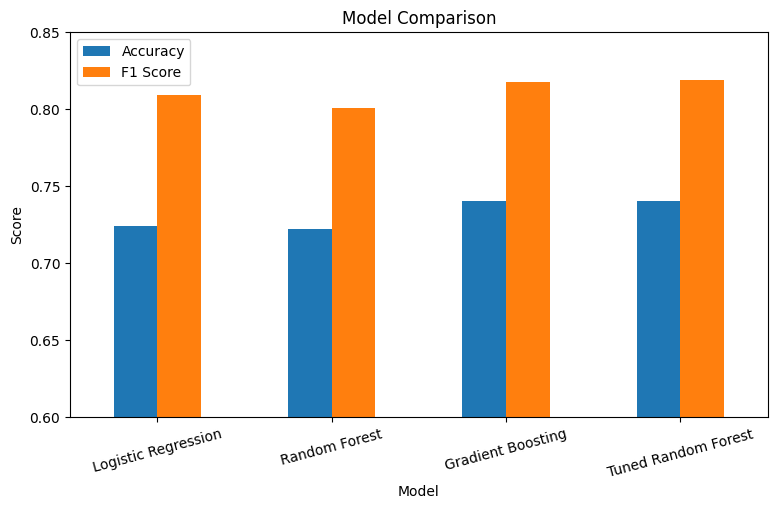

In [92]:
results.loc[len(results)] = ["Tuned Random Forest",
                             accuracy_score(y_test, tuned_pred), f1_score(y_test, tuned_pred)]

results.set_index("Model")[["Accuracy", "F1 Score"]].plot(kind="bar", figsize=(9, 5), ylim=(0.6, 0.85))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.show()

Final ML Pipeline – preprocessing + scaling + model in one object

In [93]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

feature_columns = X.columns.tolist()

def prepare(raw):
    """All our preprocessing steps in one function (same as Part 1)."""
    d = raw.copy()
    d["no_of_employees"] = d["no_of_employees"].abs()
    d["annual_wage"] = d["prevailing_wage"] * d["unit_of_wage"].map(to_annual)
    d["company_age"] = 2016 - d["yr_of_estab"]
    d["log_annual_wage"] = np.log1p(d["annual_wage"])
    d["log_no_of_employees"] = np.log1p(d["no_of_employees"])
    for col in ["has_job_experience", "requires_job_training", "full_time_position"]:
        d[col] = d[col].map({"Y": 1, "N": 0})
    d["education_of_employee"] = d["education_of_employee"].map(edu_order)
    d = pd.get_dummies(d, columns=["continent", "region_of_employment", "unit_of_wage"], dtype=int)
    return d.reindex(columns=feature_columns, fill_value=0)

# Pipeline: raw data -> preprocessing -> scaling -> best model
pipeline = Pipeline([
    ("prepare", FunctionTransformer(prepare)),
    ("scale", StandardScaler()),
    ("model", RandomForestClassifier(random_state=42, **grid.best_params_)),
])

# Train on raw data, with the same 80/20 split as before
raw_X = df.drop(columns=["case_id", "case_status"])
raw_y = (df["case_status"] == "Certified").astype(int)
rX_train, rX_test, ry_train, ry_test = train_test_split(
    raw_X, raw_y, test_size=0.2, stratify=raw_y, random_state=42)

pipeline.fit(rX_train, ry_train)
pipe_pred = pipeline.predict(rX_test)
print(f"Pipeline -> Accuracy: {accuracy_score(ry_test, pipe_pred):.4f}, F1: {f1_score(ry_test, pipe_pred):.4f}")

# Save and reload
joblib.dump(pipeline, "visa_pipeline.joblib")
final_model = joblib.load("visa_pipeline.joblib")
print("Pipeline saved and reloaded ✅")

Pipeline -> Accuracy: 0.7406, F1: 0.8193
Pipeline saved and reloaded ✅


Predictions using the Saved Pipeline (no retraining)

In [94]:
# The reloaded pipeline takes RAW data directly, with no manual preprocessing
probs = final_model.predict_proba(new_applicants)[:, 1]

for i, p in enumerate(probs, start=1):
    status = "CERTIFIED ✅" if p >= 0.5 else "DENIED ❌"
    print(f"Applicant {i}: {status}  (probability of approval: {p:.1%})")

Applicant 1: CERTIFIED ✅  (probability of approval: 92.7%)
Applicant 2: DENIED ❌  (probability of approval: 24.9%)
Applicant 3: CERTIFIED ✅  (probability of approval: 73.2%)


Interactive Web App using Gradio

In [95]:
!pip install -q gradio
import gradio as gr

yes_no = {"Yes": "Y", "No": "N"}   # the model was trained on Y/N

def predict_visa(continent, education, experience, training, employees,
                 yr_estab, region, wage, unit, full_time):
    applicant = pd.DataFrame([{
        "continent": continent, "education_of_employee": education,
        "has_job_experience": yes_no[experience],
        "requires_job_training": yes_no[training],
        "no_of_employees": employees, "yr_of_estab": yr_estab,
        "region_of_employment": region, "prevailing_wage": wage,
        "unit_of_wage": unit, "full_time_position": yes_no[full_time]}])
    p = final_model.predict_proba(applicant)[0][1]     # uses the saved pipeline

    certified = p >= 0.5
    color = "#2e7d4f" if certified else "#c0392b"
    verdict = "Likely to be Certified" if certified else "Likely to be Denied"
    return f"""
    <div class="result-card" style="border-left: 6px solid {color};">
        <div class="result-label">Prediction</div>
        <div class="result-verdict" style="color: {color};">{verdict}</div>
        <div class="result-label">Approval probability: <b>{p:.1%}</b></div>
        <div class="bar"><div class="bar-fill" style="width: {p*100:.0f}%; background: {color};"></div></div>
    </div>"""

css = """
.gradio-container {max-width: 1100px !important; margin: auto;}
#header {text-align: center; padding: 22px 0 8px;}
#header h1 {font-size: 1.9rem; font-weight: 700; color: #1f2937; margin-bottom: 6px;}
#header p {color: #6b7280; font-size: 0.95rem;}
.section-title {font-weight: 600; font-size: 1rem; color: #374151; margin-bottom: 2px;}
.result-card {padding: 18px 22px; border-radius: 10px; background: #ffffff; border: 1px solid #e5e7eb;}
.result-label {color: #6b7280; font-size: 0.9rem; margin: 4px 0;}
.result-verdict {font-size: 1.5rem; font-weight: 700; margin: 4px 0 10px;}
.bar {height: 8px; background: #eef0f3; border-radius: 6px; overflow: hidden; margin-top: 8px;}
.bar-fill {height: 100%; border-radius: 6px;}
"""

# Always open in light mode, even if the computer uses dark mode
force_light = """
() => {
    const url = new URL(window.location);
    if (url.searchParams.get('__theme') !== 'light') {
        url.searchParams.set('__theme', 'light');
        window.location.href = url.href;
    }
}
"""

theme = gr.themes.Default(primary_hue="slate", neutral_hue="gray",
                          font=[gr.themes.GoogleFont("Inter"), "sans-serif"]).set(
    body_background_fill="#f6f7f9",                 # light grey page
    block_background_fill="#ffffff",                # white cards
    block_border_color="#e5e7eb",
    block_shadow="0 1px 2px rgba(0,0,0,0.04)",
    block_title_background_fill="transparent",      # plain labels
    block_title_text_color="#4b5563",
    block_title_padding="0",
    block_label_background_fill="transparent",
    input_background_fill="#ffffff",
    input_border_color="#d1d5db",
    checkbox_label_background_fill="#ffffff",
    checkbox_label_background_fill_selected="#f1f3f5",
    checkbox_label_border_color="#d1d5db",
    checkbox_label_border_color_selected="#374151",
    button_primary_background_fill="#1f2937",       # dark grey button
    button_primary_background_fill_hover="#374151",
    button_primary_text_color="#ffffff",
)

with gr.Blocks(theme=theme, css=css, js=force_light, title="US Work Visa Approval Predictor") as app:
    gr.HTML("""
    <div id="header">
        <h1>US Work Visa Approval Predictor</h1>
        <p>Estimate the outcome of a US employment-based visa application from applicant, employer and job details.</p>
    </div>""")

    with gr.Row():
        with gr.Column():
            gr.Markdown("<div class='section-title'>Applicant</div>")
            continent = gr.Dropdown(["Asia", "Europe", "North America", "South America", "Africa", "Oceania"],
                                    value="Asia", label="Home continent")
            education = gr.Dropdown(["High School", "Bachelor's", "Master's", "Doctorate"],
                                    value="Bachelor's", label="Education")
            experience = gr.Radio(["Yes", "No"], value="Yes", label="Has job experience")

        with gr.Column():
            gr.Markdown("<div class='section-title'>Employer (US company)</div>")
            employees = gr.Number(value=2000, label="Number of employees", precision=0)
            yr_estab = gr.Number(value=2000, label="Year established", precision=0)
            region = gr.Dropdown(["Northeast", "South", "West", "Midwest", "Island"],
                                 value="Northeast", label="Region of employment")

        with gr.Column():
            gr.Markdown("<div class='section-title'>Job offer</div>")
            wage = gr.Number(value=70000, label="Prevailing wage (USD)")
            unit = gr.Dropdown(["Year", "Month", "Week", "Hour"], value="Year", label="Wage unit")
            full_time = gr.Radio(["Yes", "No"], value="Yes", label="Full-time position")
            training = gr.Radio(["Yes", "No"], value="No", label="Requires job training")

    predict_btn = gr.Button("Predict Visa Status", variant="primary", size="lg")
    result = gr.HTML("<div class='result-card'><div class='result-label'>Fill in the details and click Predict.</div></div>")

    predict_btn.click(predict_visa,
                      inputs=[continent, education, experience, training, employees,
                              yr_estab, region, wage, unit, full_time],
                      outputs=result)

    gr.Markdown("<p style='text-align:center; color:#9ca3af; font-size:0.85rem;'>"
                "Model: tuned Random Forest pipeline trained on the EasyVisa dataset (US Department of Labor, OFLC). "
                "Applicants may be from any country; the destination is always the USA.</p>")

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: (temporary demo link removed)

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
